# Campaign throughput and resource usage

Qwen3.5-9B · SWE-bench Pro V2 · native AgentENV · two GH200 nodes / eight GPUs.
Campaign: `sandbox-sweep-20261015_193213Z`; 128 fixed groups × 8 episodes per point.

Both panels show configured concurrent episode ceilings **64, 128, 256, 512**.
All bars at **512** are hatched to mark its `vLLM EngineDeadError`; these are
observations from the failed run, not healthy sustained-throughput measurements.

- **Throughput:** paired bars show completed terminal attempts per minute (including errors)
  and reward-verified episodes per minute (completed reward evaluation, including reward zero);
  excludes model/framework initialization. This measures the training rollout pipeline,
  without an optimizer or backward pass. Both series count episodes, not groups;
  a finished group does not guarantee completed verification for all eight episodes.
- **GPU SM Activity:** mean DCGM SM activity percentage over complete one-minute bins within
  the rollout window, using the campaign's GPU aggregation.
- **CPU utilization:** mean sandbox-host CPU busy percentage over complete one-minute
  bins within the rollout window, across all 96 logical CPUs; includes guest execution
  and host overhead, rather than only `aenv.service`.
- **Peak anonymous memory:** independent maximum of `aenv.service` cgroup
  `memory.stat` → `anon`, sampled every 5 seconds within the rollout window, in GiB.
  It excludes charged file cache and kernel memory and is not total charged memory.

The resource panel uses **separate Y-axes**: CPU/GPU percent on the left and memory GiB
on the right. Bar heights across the two units do not represent a common magnitude.
Style follows `flash-sandbox/meta/plot/3_paper/1_characterization.ipynb`:
9 × 3.75 inches, Roboto, paper context at font scale 2, and the same palette.

In [32]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

REPO = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'uni_agent').is_dir() and (p / 'meta/plot').is_dir())
PLOT = REPO / 'meta/plot'
DATA = PLOT / 'data/sandbox_sweep_20261015.csv'
FIGURES = PLOT / 'figure'
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_style('ticks')
sns.set_style({'font.family': ['Roboto', 'DejaVu Sans'], 'font.size': 12})
sns.set_context('paper', font_scale=2,
                rc={'lines.linewidth': 3, 'lines.markersize': 10})
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'legend.frameon': False, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'svg.fonttype': 'none',
})
PALETTE = {
    'blue_main': '#0F4D92', 'blue_secondary': '#3775BA',
    'green_1': '#DDF3DE', 'green_2': '#AADCA9', 'green_3': '#8BCF8B',
    'red_1': '#F6CFCB', 'red_2': '#E9A6A1', 'red_strong': '#B64342',
    'neutral': '#CFCECE', 'highlight': '#FFD700',
    'teal': '#42949E', 'violet': '#9A4D8E',
}

In [33]:
provenance = json.loads(DATA.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(DATA.read_bytes()).hexdigest() == provenance['sha256']
runs = pd.read_csv(DATA).sort_values('episode_ceiling').reset_index(drop=True)
assert runs.episode_ceiling.tolist() == [64, 128, 256, 512]
assert (runs.episode_ceiling == runs.active_groups * 8).all()
assert (runs.state == 'completed').all() and (runs.groups_terminal == 128).all()
assert (runs.completed_episodes == 1024).all() and (runs.wall_seconds > 0).all()
for count, rate in [
    ('completed_episodes', 'completed_episodes_per_minute'),
    ('verified_episodes', 'verified_episodes_per_minute'),
    ('usable_episodes', 'usable_episodes_per_minute'),
]:
    assert np.allclose(runs[rate], 60 * runs[count] / runs.wall_seconds)
assert (runs.verified_episodes + runs.incomplete_verifications == runs.completed_episodes).all()

memory_path = PLOT / 'data/sandbox_sweep_20261015_memory.csv'
memory_provenance = json.loads(memory_path.with_suffix('.provenance.json').read_text())
assert hashlib.sha256(memory_path.read_bytes()).hexdigest() == memory_provenance['sha256']
memory = pd.read_csv(memory_path)
assert memory.episode_ceiling.is_unique
runs = runs.merge(memory, on='episode_ceiling', validate='one_to_one')
selected = runs.copy()
display(selected[[
    'episode_ceiling', 'completed_episodes_per_minute',
    'verified_episodes_per_minute', 'rollout_sm_active_pct_mean',
    'sandbox_cpu_busy_pct_mean', 'peak_anonymous_memory_gib',
]].round(2))

,episode_ceiling,completed_episodes_per_minute,verified_episodes_per_minute,rollout_sm_active_pct_mean,sandbox_cpu_busy_pct_mean,peak_anonymous_memory_gib
0,64,28.62,24.79,7.63,40.86,69.75
1,128,56.99,43.63,11.39,90.37,109.18
2,256,80.05,41.90,15.00,95.25,174.60
3,512,77.06,36.80,6.96,85.38,198.59


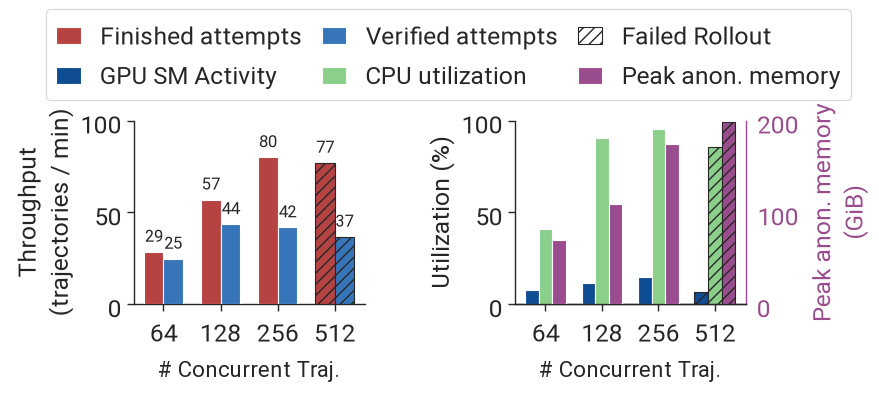

In [34]:
from matplotlib.patches import Patch

fig, (throughput_ax, gpu_ax) = plt.subplots(1, 2, figsize=(9, 3.75))
fig.subplots_adjust(left=.15, right=.83, bottom=.23, top=.72, wspace=.65)
memory_ax = gpu_ax.twinx()
x = np.arange(len(selected))
width = .24
for axis in (throughput_ax, gpu_ax):
    axis.set_xticks(x, selected.episode_ceiling.astype(str))
    axis.set_xlabel('# Concurrent Traj.', fontsize=16)

throughput_bars = throughput_ax.bar(
    x - .17, selected.completed_episodes_per_minute, width=.34,
    color=PALETTE['red_strong'], label='Finished attempts', zorder=3)
verified_bars = throughput_ax.bar(
    x + .17, selected.verified_episodes_per_minute, width=.34,
    color=PALETTE['blue_secondary'], label='Verified attempts', zorder=3)
gpu_bars = gpu_ax.bar(
    x - width, selected.rollout_sm_active_pct_mean, width=width,
    color=PALETTE['blue_main'], label='GPU SM Activity', zorder=3)
cpu_bars = gpu_ax.bar(
    x, selected.sandbox_cpu_busy_pct_mean, width=width,
    color=PALETTE['green_3'], label='CPU utilization', zorder=3)
memory_bars = memory_ax.bar(
    x + width, selected.peak_anonymous_memory_gib, width=width,
    color=PALETTE['violet'], label='Peak anon. memory', zorder=3)

# Hatch every metric at 512; preserve its measured height and series color.
failed_index = selected.episode_ceiling.tolist().index(512)
for bars in (throughput_bars, verified_bars, gpu_bars, cpu_bars, memory_bars):
    bars[failed_index].set_hatch('///')
    bars[failed_index].set_edgecolor('#272727')
    bars[failed_index].set_linewidth(.8)
failed_handle = Patch(facecolor='white', edgecolor='#272727', hatch='///', label='Failed Rollout')
throughput_ax.set(ylabel='Throughput\n(trajectories / min)', ylim=(0, 100))
gpu_ax.set(ylabel='Utilization (%)', ylim=(0, 100))
memory_ax.set(ylabel='Peak anon. memory\n(GiB)', ylim=(0, 200))
for axis in (throughput_ax, gpu_ax, memory_ax):
    axis.yaxis.label.set_fontsize(17.6)
gpu_ax.yaxis.label.set_color('#272727')
gpu_ax.tick_params(axis='y', colors='#272727')
memory_ax.yaxis.label.set_color(PALETTE['violet'])
memory_ax.tick_params(axis='y', colors=PALETTE['violet'])
sns.despine(ax=throughput_ax)
sns.despine(ax=gpu_ax)
sns.despine(ax=memory_ax, left=True, right=False)
memory_ax.spines['right'].set_color(PALETTE['violet'])
gpu_ax.spines['left'].set_color('#272727')
for bars in (throughput_bars, verified_bars):
    throughput_ax.bar_label(bars, fmt='%.0f', padding=4, fontsize=12)
legend_order = [throughput_bars, verified_bars,failed_handle, gpu_bars,
                cpu_bars, memory_bars]
legend_handles = [legend_order[i] for i in (0, 3, 1, 4, 2, 5)]
fig.legend(handles=legend_handles, loc='upper center',
           bbox_to_anchor=(.5, 1.05), ncol=3, fontsize=17.6,
           columnspacing=.8, handlelength=1.0, labelspacing=.3, frameon=True)
for extension in ('pdf', 'png'):
    fig.savefig(FIGURES / f'concurrency_throughput.{extension}', dpi=300,
                facecolor='white', bbox_inches='tight')
display(fig)
plt.close(fig)

Completed-attempt throughput rises from **28.62** to **56.99** to **80.05 episodes/min**.
Reward-verified throughput is **24.79**, **43.63**, and **41.90 episodes/min**, respectively.
Mean GPU SM activity rises from **7.63%** to **11.39%** to **15.00%**;
mean sandbox-host CPU utilization rises from **40.86%** to **90.37%** to **95.25%**;
peak cgroup anonymous memory rises from **69.75** to **109.18** to **174.60 GiB**.

These are single ordered runs, without estimated uncertainty. Completed attempts include errors;
reward-verification rates do not follow the same increase. Stochastic trajectories,
incomplete verification, and cache warming limit causal interpretation.
All jobs reported failure during Ray teardown after results were written;
the hatched 512 point had a separate workload engine failure.
At 512, completed-attempt and reward-verified rates were **77.06** and **36.80 episodes/min**;
mean GPU SM activity was **6.96%**, mean CPU utilization **85.38%**,
and peak anonymous memory **198.59 GiB**. Only 319/1,024 attempts had stored trajectories.

The adjacent frozen CSVs and provenance JSONs record the inputs and memory extraction windows.
Exports: `figure/campaign_throughput.{pdf,png,svg}`; fixed 9 × 3.75-inch canvas,
300-DPI PNG, and editable vector text.